# Identyfikacja wzorców i anomalii w deformacjach terenu na podstawie danych EGMS

## Cel ćwiczenia

W ćwiczeniu analizujemy szeregi czasowe przemieszczeń punktów PS-InSAR pochodzących z danych EGMS. Celem jest rozpoznanie różnych sposobów zachowania punktów w czasie oraz wskazanie tych, których przebieg deformacji różni się od typowego zachowania obserwowanego w analizowanym zbiorze.

Analiza ma odpowiedzieć na dwa główne pytania:

1. **Które punkty PS wykazują nietypowe zachowanie deformacyjne?**
Do ich identyfikacji wykorzystamy metodę Isolation Forest, która pozwala wskazać obserwacje różniące się od większości punktów pod względem analizowanych cech szeregu czasowego.

2. **Jakie typowe wzorce zachowania występują wśród punktów PS?**
Za pomocą metody K-means pogrupujemy punkty o podobnych charakterystykach deformacji i porównamy przebieg ich szeregów czasowych.



EGMS: https://egms.land.copernicus.eu/

Budynki: https://eubucco.com/data/download/v0.2

Dokumentacja: https://land.copernicus.eu/en/products/european-ground-motion-service?tab=documentation

## Wersja dla Łęcznej — ważna uwaga o zasięgu

Plik wejściowy `EGMS_L3_E52N32_100km_E_2020_2024_1.csv` zawiera **62 226 punktów w kaflu EGMS 100 × 100 km**, a nie wyłącznie w poligonie zaznaczonym na mapie. W pierwszej wersji `AOI_BOUNDS = None`, więc analizowany jest cały kafel. Przed interpretacją wyników jako wyników dla wybranej strefy należy ustawić granice AOI albo dodać dokładny poligon i wykonać filtrowanie przestrzenne.

Pozostałe elementy zachowują logikę notebooka dydaktycznego. Liczba klastrów `k=4` jest jedynie wartością początkową i powinna zostać oceniona na wykresach elbow oraz silhouette.


# ETAP 1 — Import i kontrola danych





In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [32]:
# Dane EGMS dla obszaru Łęcznej.
INPUT_CSV = "EGMS_L3_E52N32_100km_E_2020_2024_1/EGMS_L3_E52N32_100km_E_2020_2024_1.csv"
OUTPUT_CSV = "EGMS_Leczna_results.csv"

df = pd.read_csv(INPUT_CSV)

# Zgodność z ewentualnymi starszymi nazwami kolumn z przykładu Bytomia.
df = df.rename(columns={
    "height_ort": "height_ortho",
    "mean_veloc": "mean_velocity",
    "mean_vel_1": "mean_velocity_std",
    "accelerati": "acceleration",
    "accelera_1": "acceleration_std",
    "seasonalit": "seasonality",
    "seasonal_1": "seasonality_std",
    "gnss_veloc": "gnss_velocity_n",
    "gnss_vel_1": "gnss_velocity_e",
    "gnss_vel_2": "gnss_velocity_u"
})

# WAŻNE: plik wejściowy jest kaflem EGMS 100 km, a nie samym poligonem
# wybranym na mapie. Po uzyskaniu dokładnego poligonu AOI można tu podać
# granice w układzie współrzędnych EGMS: (min_easting, min_northing,
# max_easting, max_northing). Przy None analizowany będzie cały kafel.
AOI_BOUNDS = None

if AOI_BOUNDS is not None:
    min_x, min_y, max_x, max_y = AOI_BOUNDS
    df = df[
        df["easting"].between(min_x, max_x)
        & df["northing"].between(min_y, max_y)
    ].copy()

required_cols = [
    "pid", "easting", "northing", "rmse_ts",
    "mean_velocity", "acceleration", "seasonality"
]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Brak wymaganych kolumn: {missing_cols}")

if df.empty:
    raise ValueError("Po wczytaniu lub filtrowaniu nie pozostały żadne punkty.")

print("Plik wejściowy:", INPUT_CSV)
print("Liczba punktów PS:", len(df))
print("Liczba wszystkich kolumn:", len(df.columns))
print("Zakres easting:", df["easting"].min(), "–", df["easting"].max())
print("Zakres northing:", df["northing"].min(), "–", df["northing"].max())
if AOI_BOUNDS is None:
    print("UWAGA: nie zastosowano filtra AOI — analizowany jest cały kafel EGMS.")
df.head()


Plik wejściowy: EGMS_L3_E52N32_100km_E_2020_2024_1/EGMS_L3_E52N32_100km_E_2020_2024_1.csv
Liczba punktów PS: 62226
Liczba wszystkich kolumn: 277
Zakres easting: 5200050.0 – 5285950.0
Zakres northing: 3200050.0 – 3299950.0
UWAGA: nie zastosowano filtra AOI — analizowany jest cały kafel EGMS.


,pid,easting,northing,height_ortho,rmse_ts,mean_velocity,mean_velocity_std,acceleration,acceleration_std,seasonality,...,20241025,20241031,20241106,20241112,20241118,20241124,20241130,20241206,20241212,20241218
0,30d1glmaRO,5225850.0,3200050.0,176.0,1.8,0.5,0.1,-0.25,0.12,0.8,...,4.1,3.6,3.1,2.0,1.0,1.0,1.6,2.2,2.6,3.0
1,30d1q974nm,5215050.0,3200250.0,194.0,2.6,-0.1,0.1,0.42,0.18,1.1,...,1.9,3.0,2.8,1.9,1.6,1.9,1.8,0.0,-1.4,2.4
2,30d1upmJyN,5205950.0,3200350.0,188.0,2.7,-0.9,0.1,0.36,0.19,0.6,...,8.5,4.8,-0.5,-1.4,-1.2,-1.2,-1.6,-1.1,-0.8,-2.0
3,30d1zWRZAX,5206550.0,3200450.0,183.0,3.2,-0.5,0.1,0.83,0.22,2.7,...,3.5,3.2,3.3,1.4,0.5,1.5,1.5,2.2,3.0,3.4
4,30d1zWRZBb,5213150.0,3200450.0,201.0,2.4,-0.2,0.1,-0.67,0.17,2.0,...,-3.0,-1.8,-0.3,2.5,5.2,4.7,3.6,2.2,0.8,0.9


In [4]:
date_cols = [
    col for col in df.columns
    if str(col).isdigit() and len(str(col)) == 8
]

dates = pd.to_datetime(date_cols, format="%Y%m%d")


print("Liczba punktów PS:", len(df))
print("Liczba obserwacji czasowych:", len(date_cols))
print("Pierwsza obserwacja:", dates.min().date())
print("Ostatnia obserwacja:", dates.max().date())
print("Braki w szeregu czasowym:", df[date_cols].isna().sum().sum())

Liczba punktów PS: 62226
Liczba obserwacji czasowych: 263
Pierwsza obserwacja: 2020-02-07
Ostatnia obserwacja: 2024-12-18
Braki w szeregu czasowym: 0


## Podstawowe parametry EGMS

Przegląd parametrów dostarczonych wraz z danymi. Szczególnie ważne są:

- `mean_velocity` — średnia prędkość przemieszczenia,
- `acceleration` — informacja o zmianie prędkości,
- `seasonality` — amplituda zachowania sezonowego,
- `rmse_ts` — parametr jakości/rozrzutu dopasowania szeregu.



In [5]:
basic_features = ["mean_velocity", "acceleration", "seasonality", "rmse_ts"]
df[basic_features].describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
mean_velocity,62226.0,-0.479,1.680,-31.9,-0.90,-0.5,0.00,36.70
acceleration,62226.0,-0.002,0.578,-5.3,-0.25,-0.0,0.24,5.67
seasonality,62226.0,0.774,0.639,0.0,0.30,0.6,1.00,8.90
rmse_ts,62226.0,1.609,0.850,0.3,0.90,1.4,2.10,4.50


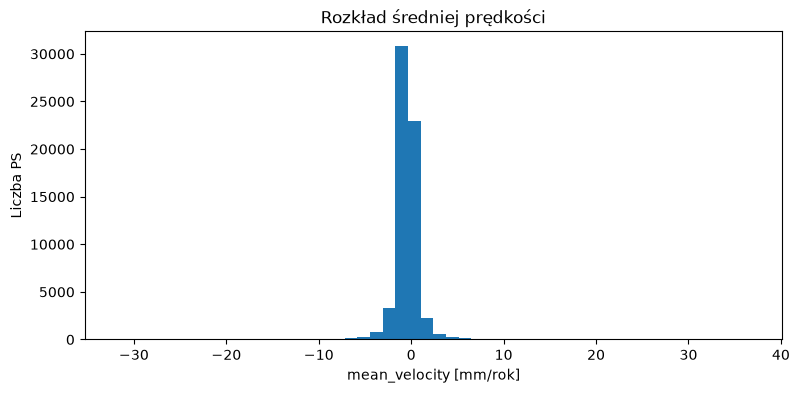

In [6]:
plt.figure(figsize=(9, 4))
plt.hist(df["mean_velocity"], bins=50)
plt.xlabel("mean_velocity [mm/rok]")
plt.ylabel("Liczba PS")
plt.title("Rozkład średniej prędkości")
plt.show()


## Oglądanie pojedynczego szeregu czasowego

Funkcja `plot_ps()` będzie również używana później do kontroli punktów wskazanych przez model.


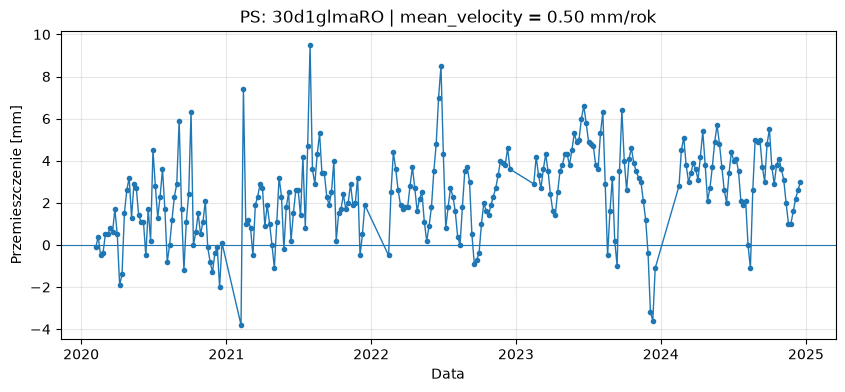

In [7]:
def plot_ps(pid):
    row = df[df["pid"] == pid].iloc[0]
    y = row[date_cols].astype(float).values

    plt.figure(figsize=(10, 4))
    plt.plot(dates, y, marker=".", linewidth=1)
    plt.axhline(0, linewidth=0.8)
    plt.xlabel("Data")
    plt.ylabel("Przemieszczenie [mm]")
    plt.title(
        f"PS: {pid} | mean_velocity = {row['mean_velocity']:.2f} mm/rok"
    )
    plt.grid(alpha=0.3)
    plt.show()

plot_ps(df.iloc[0]["pid"])


# ETAP 2 — Zamiana szeregu czasowego na informacje

Model nie otrzymuje całego szeregu 239 obserwacji bezpośrednio. Najpierw musimy stworzyć kilka **interpretowalnych cech**, które opisują zachowanie punktu PS. W ML nazywamy to **feature engineeringiem**.


In [8]:
# Rzeczywisty czas w latach od pierwszej obserwacji.
# Dzięki temu regresja uwzględnia faktyczne odstępy między datami.
time_years = ((dates - dates.min()).days / 365.25).to_numpy()

# Tworzymy funkcję do wyznaczania trendu liniowego dla dowolnego fragmentu szeregu czasowego.
# Nachylenie trendu (slope) jest wyrażone w mm/rok. Dla całego szeregu opisuje długookresowe tempo
# zmian i może być zbliżone do mean_velocity dostarczonego przez EGMS. Funkcja będzie jednak
# potrzebna przede wszystkim do porównywania trendów wyznaczonych dla różnych okresów oraz do oceny
# ich regularności za pomocą R².

def fit_linear_trend(values, time_values):
    y = np.asarray(values, dtype=float)
    t = np.asarray(time_values, dtype=float)

    mask = np.isfinite(y) & np.isfinite(t)
    y = y[mask]
    t = t[mask]

    if len(y) < 3 or np.unique(t).size < 2:
        return np.nan, np.nan

    model = LinearRegression()
    model.fit(t.reshape(-1, 1), y)

    slope = model.coef_[0]
    r2 = model.score(t.reshape(-1, 1), y)

    return slope, r2

## 2A. Trend całego okresu

`trend` jest nachyleniem regresji liniowej dopasowanej do **wszystkich obserwacji** punktu PS i ma jednostkę mm/rok.

`trend_R2` informuje, jak dobrze prosty trend liniowy opisuje cały przebieg. Niskie `R²` nie oznacza automatycznie błędnych danych — przebieg może być nieliniowy lub zmienny w czasie.


In [9]:
global_results = df.apply(
    lambda row: fit_linear_trend(row[date_cols].values, time_years),
    axis=1
)

df["trend"] = [x[0] for x in global_results]
df["trend_R2"] = [x[1] for x in global_results]

df[["pid", "mean_velocity", "trend", "trend_R2"]].head()


C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\2363804231.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["trend"] = [x[0] for x in global_results]
C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\2363804231.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["trend_R2"] = [x[1] for x in global_results]


,pid,mean_velocity,trend,trend_R2
0,30d1glmaRO,0.5,0.509703,0.134884
1,30d1q974nm,-0.1,-0.098884,0.002674
2,30d1upmJyN,-0.9,-0.884294,0.173246
3,30d1zWRZAX,-0.5,-0.345253,0.016654
4,30d1zWRZBb,-0.2,-0.263672,0.017296


In [10]:
correlation = df["trend"].corr(
    df["mean_velocity"]
)

print(
    "Korelacja trend vs mean_velocity:",
    round(correlation, 3)
)

Korelacja trend vs mean_velocity: 1.0


## 2B. Trendy w kolejnych latach

Dla każdego roku dopasowujemy osobną prostą do wszystkich obserwacji z tego roku. Nie interesuje nas pojedynczy skok, lecz **tempo zmian w dłuższym fragmencie szeregu**.


In [11]:
years = sorted(pd.Index(dates.year).unique())
yearly_trend_cols = []

for year in years:
    mask = dates.year == year
    cols_year = [col for col, keep in zip(date_cols, mask) if keep]
    dates_year = dates[mask]
    time_year = ((dates_year - dates_year.min()).days / 365.25).to_numpy()

    col_name = f"trend_{year}"
    yearly_trend_cols.append(col_name)

    df[col_name] = df.apply(
        lambda row: fit_linear_trend(row[cols_year].values, time_year)[0],
        axis=1
    )

print("Analizowane lata:", years)
df[["pid"] + yearly_trend_cols].head()


C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col_name] = df.apply(
C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col_name] = df.apply(
C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider

Analizowane lata: [2020, 2021, 2022, 2023, 2024]


C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\666787241.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col_name] = df.apply(


,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024
0,30d1glmaRO,-0.055457,1.280623,0.147081,-3.496687,-1.625949
1,30d1q974nm,0.268699,-3.132103,-5.950293,-0.390051,2.852492
2,30d1upmJyN,-1.062963,-3.649457,-5.304279,-2.182311,4.486757
3,30d1zWRZAX,0.174260,2.748750,7.748011,8.904391,12.924699
4,30d1zWRZBb,0.752729,-0.334759,-6.884233,-5.464873,-0.789977


### Ewolucja trendów rocznych

Z pięciu trendów rocznych tworzymy jedną prostą cechę: `annual_trend_slope`.

- wartość **ujemna**: trendy roczne stają się z czasem bardziej ujemne,
- wartość **dodatnia**: trendy roczne przesuwają się w stronę bardziej dodatnich wartości,
- wartość bliska **0**: brak wyraźnego kierunku zmian między latami.

Dodatkowo liczymy `annual_trend_R2` jako cechę diagnostyczną: pokazuje, czy zmiana trendów rocznych jest systematyczna.

In [12]:
### Zmienność rocznych trendów

# Dla każdego punktu PS obliczono odchylenie standardowe rocznych prędkości przemieszczenia. Parametr `annual_trend_std` opisuje, jak silnie różniły się prędkości wyznaczone w kolejnych latach.
# Niska wartość oznacza podobne tempo przemieszczeń w kolejnych latach, natomiast wysoka wartość wskazuje na większą zmienność
# międzyroczną lub wystąpienie roku wyraźnie różniącego się od pozostałych.

df["annual_trend_std"] = (
    df[yearly_trend_cols]
    .std(axis=1)
)

df[
    ["pid"]
    + yearly_trend_cols
    + ["annual_trend_std"]
].head()

C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\3718786268.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["annual_trend_std"] = (


,pid,trend_2020,trend_2021,trend_2022,trend_2023,trend_2024,annual_trend_std
0,30d1glmaRO,-0.055457,1.280623,0.147081,-3.496687,-1.625949,1.852171
1,30d1q974nm,0.268699,-3.132103,-5.950293,-0.390051,2.852492,3.373034
2,30d1upmJyN,-1.062963,-3.649457,-5.304279,-2.182311,4.486757,3.727650
3,30d1zWRZAX,0.174260,2.748750,7.748011,8.904391,12.924699,5.067106
4,30d1zWRZBb,0.752729,-0.334759,-6.884233,-5.464873,-0.789977,3.398341


## 2C. Ostatnie 12 miesięcy względem wcześniejszego okresu

Sprawdzamy, czy zachowanie punktu PS w ostatnich 12 miesiącach różniło się od jego wcześniejszego, długoterminowego zachowania.

`baseline_velocity` jest trendem dopasowanym do wszystkich obserwacji wcześniejszych niż ostatnie 12 miesięcy.

`recent_velocity` jest trendem dopasowanym do obserwacji z ostatnich 12 miesięcy.

Zmianę trendu obliczamy jako:

`trend_change = recent_velocity - baseline_velocity`

Wartość ujemna oznacza, że trend w ostatnich 12 miesiącach stał się bardziej ujemny. Wartość dodatnia oznacza, że trend stał się mniej ujemny lub bardziej dodatni.


In [13]:
last_date = dates.max()
recent_start = last_date - pd.DateOffset(years=1)

# Podział obserwacji na okres wcześniejszy i ostatnie 12 miesięcy
baseline_mask = dates < recent_start
recent_mask = dates >= recent_start

baseline_cols = [col for col, keep in zip(date_cols, baseline_mask) if keep]
recent_cols = [col for col, keep in zip(date_cols, recent_mask) if keep]

baseline_dates = dates[baseline_mask]
recent_dates = dates[recent_mask]

baseline_time = ((baseline_dates - baseline_dates.min()).days / 365.25).to_numpy()
recent_time = ((recent_dates - recent_dates.min()).days / 365.25).to_numpy()

# Trendy dla obu okresów
df["baseline_velocity"] = df.apply(
    lambda row: fit_linear_trend(row[baseline_cols].values, baseline_time)[0],
    axis=1
)

df["recent_velocity"] = df.apply(
    lambda row: fit_linear_trend(row[recent_cols].values, recent_time)[0],
    axis=1
)

# Zmiana trendu w ostatnich 12 miesiącach
df["trend_change"] = df["recent_velocity"] - df["baseline_velocity"]

print("Okres bazowy:", baseline_dates.min().date(), "–", baseline_dates.max().date())
print("Okres ostatni:", recent_dates.min().date(), "–", recent_dates.max().date())

df[
    ["pid", "baseline_velocity", "recent_velocity", "trend_change"]
].head()

C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\2858193530.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["baseline_velocity"] = df.apply(


Okres bazowy: 2020-02-07 – 2023-12-12
Okres ostatni: 2023-12-18 – 2024-12-18


C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\2858193530.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["recent_velocity"] = df.apply(
C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\2858193530.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["trend_change"] = df["recent_velocity"] - df["baseline_velocity"]


,pid,baseline_velocity,recent_velocity,trend_change
0,30d1glmaRO,0.619718,-0.748056,-1.367775
1,30d1q974nm,-0.383696,2.978442,3.362138
2,30d1upmJyN,-1.262482,3.928613,5.191095
3,30d1zWRZAX,-0.611720,10.574987,11.186707
4,30d1zWRZBb,-0.111586,-1.531335,-1.419749


# ETAP 3 — Wybór cech

Finalny model wykorzystuje mały zestaw cech, z których każda ma czytelną interpretację:

- `mean_velocity` — przeciętne tempo ruchu,
- `acceleration` — zmiana prędkości,
- `trend_change` — różnica między ostatnimi 12 miesiącami a trendem długoterminowym.

`rmse_ts`, `seasonality`,`trend_R2` pozostaje poza modelem i służy później do kontroli jakości wyniku.

Przed modelowaniem sprawdzamy korelacje. Silna korelacja nie oznacza automatycznie, że jedna zmienna jest błędna, ale pomaga zauważyć redundancję.


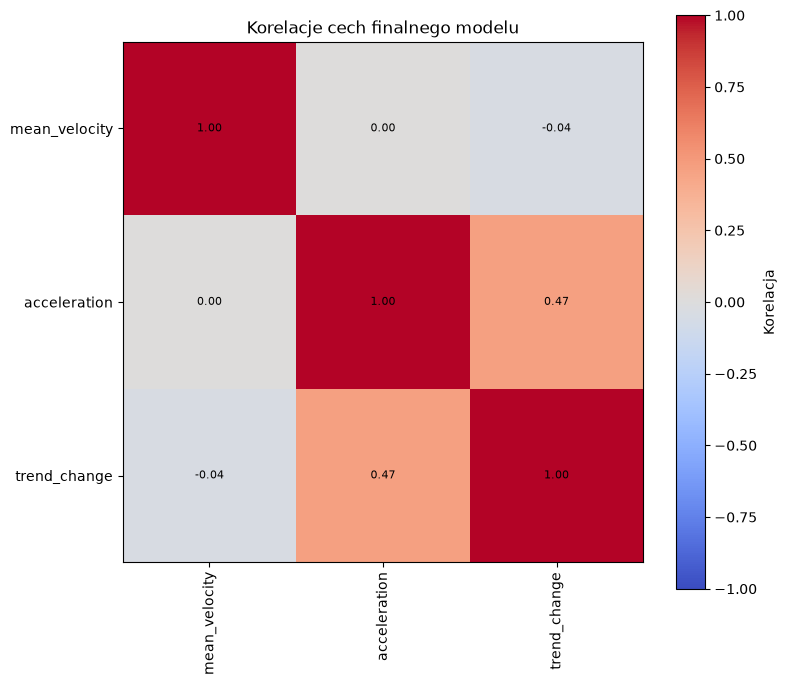

In [14]:
model_features = [
    "mean_velocity",
    "acceleration",
    "trend_change"
]

control_features = [
    "rmse_ts",
    "trend_R2",
    "seasonality"
]

corr_features = model_features
corr = df[corr_features].corr()

plt.figure(figsize=(8, 7))
plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Korelacja")

plt.xticks(range(len(corr_features)), corr_features, rotation=90)
plt.yticks(range(len(corr_features)), corr_features)

for i in range(len(corr_features)):
    for j in range(len(corr_features)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)

plt.title("Korelacje cech finalnego modelu")
plt.tight_layout()
plt.show()


# ETAP 4 — Isolation Forest: wykrywanie nietypowych PS

Isolation Forest jest metodą **uczenia nienadzorowanego**. Nie mamy etykiet „uszkodzony / nieuszkodzony”, dlatego model nie uczy się uszkodzeń.

Model odpowiada na pytanie:

> **Które PS mają nietypową kombinację cech deformacyjnych na tle całego zbioru?**

`anomaly_score` traktujemy jako wynik ciągły: im wyższy, tym bardziej nietypowy punkt.


In [15]:
X_if = df[model_features].copy()

if X_if.isna().any().any():
    raise ValueError(
        "Cechy modelu zawierają braki danych. "
        "Sprawdź model_features przed uruchomieniem Isolation Forest."
    )

iso_forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42
)

iso_forest.fit(X_if)

# Odwrócenie znaku: wyższy wynik oznacza bardziej nietypowy PS
df["anomaly_score"] = -iso_forest.score_samples(X_if)

C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\461801728.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["anomaly_score"] = -iso_forest.score_samples(X_if)


Za anomalne przyjmujemy umownie 5% PS o najwyższym anomaly_score. Nie oznacza to, że 5% punktów reprezentuje rzeczywistą anomalną deformację, jest to próg służący do wyboru punktów do dalszej analizy.

In [16]:
threshold = df["anomaly_score"].quantile(0.95)

df["anomaly"] = df["anomaly_score"] >= threshold

print("Próg anomaly_score:", round(threshold, 3))
print(df["anomaly"].value_counts())

Próg anomaly_score: 0.567
anomaly
False    59114
True      3112
Name: count, dtype: int64


C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\3627826638.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["anomaly"] = df["anomaly_score"] >= threshold


## Kontrola wyniku

Isolation Forest wskazuje punkty nietypowe na podstawie kombinacji analizowanych cech. Sam wysoki anomaly_score nie oznacza jednak automatycznie anomalnej deformacji. Dlatego sprawdzimy:
1. Czy anomaly_score jest związany z RMSE szeregu czasowego?
2. Jak wyglądają rzeczywiste szeregi czasowe punktów o najwyższym anomaly_score?
3. Czy model wskazuje wyłącznie PS o najbardziej ujemnym mean_velocity?

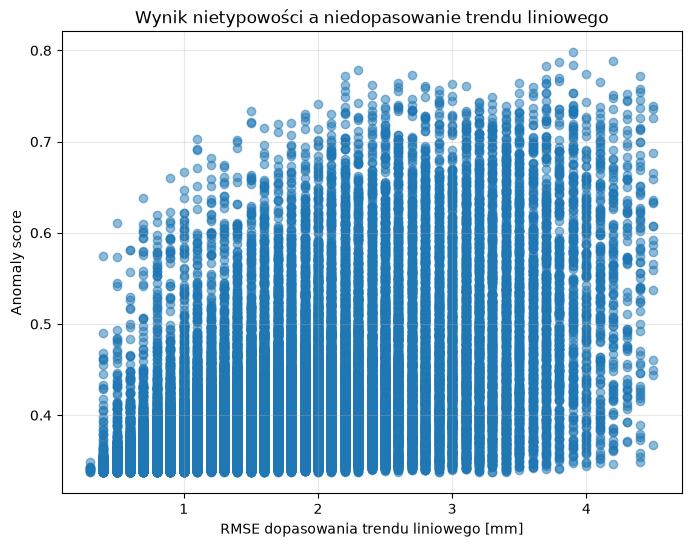

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["rmse_ts"],
    df["anomaly_score"],
    alpha=0.5
)

plt.xlabel("RMSE dopasowania trendu liniowego [mm]")
plt.ylabel("Anomaly score")
plt.title("Wynik nietypowości a niedopasowanie trendu liniowego")
plt.grid(alpha=0.3)

plt.show()

In [18]:
corr_rmse = df["anomaly_score"].corr(df["rmse_ts"])

print("Korelacja anomaly_score vs RMSE:",
      round(corr_rmse, 3))

Korelacja anomaly_score vs RMSE: 0.597


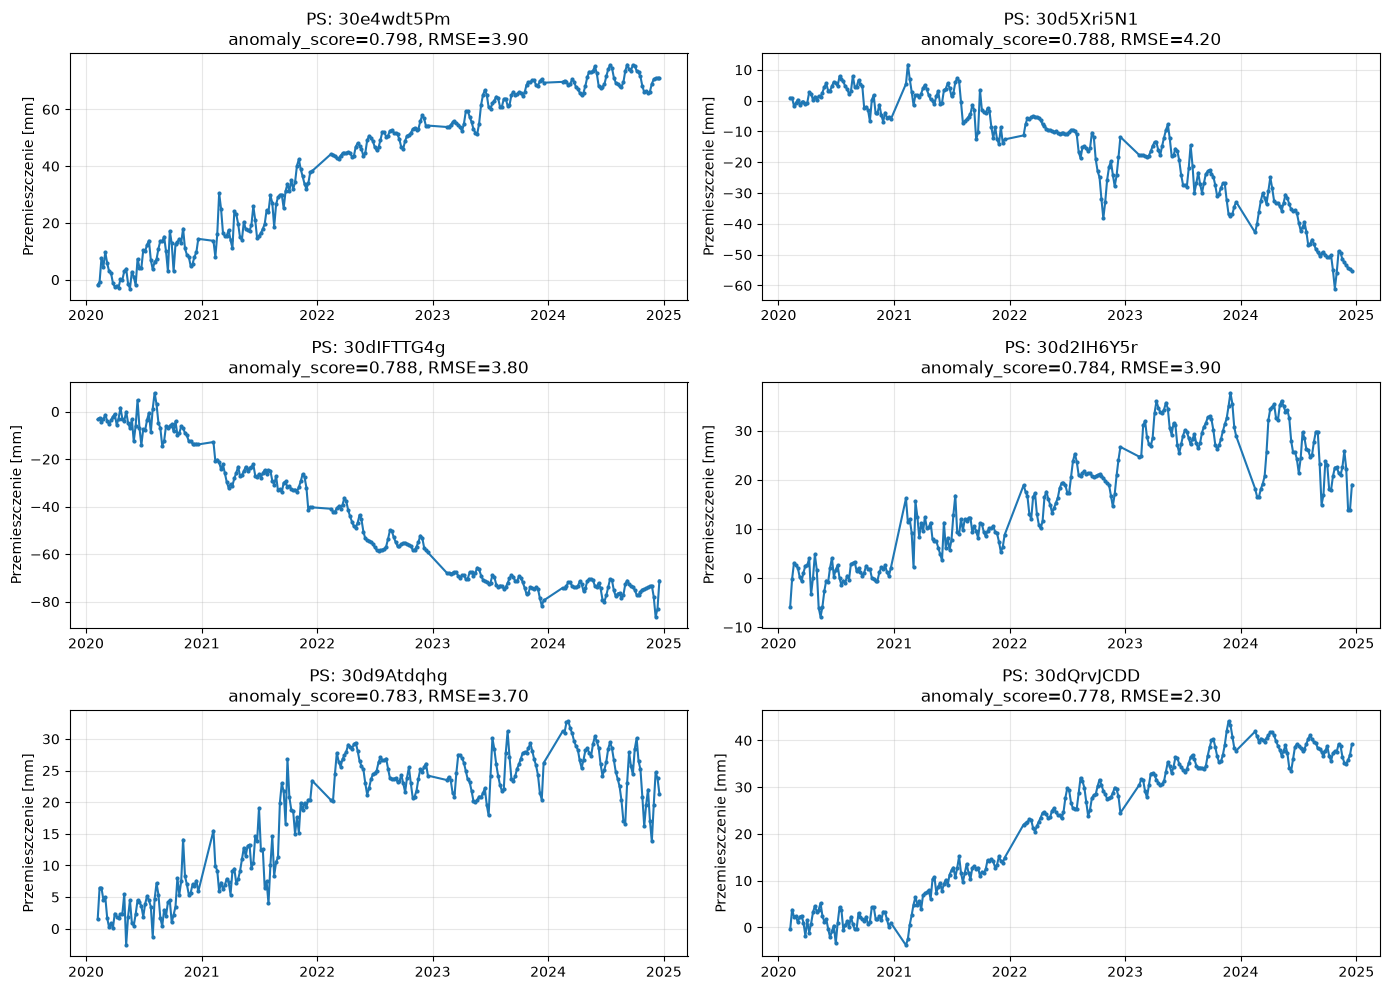

In [19]:
### Kontrola szeregów czasowych punktów o najwyższym wyniku nietypowości

top_anomalies = df.nlargest(6, "anomaly_score")

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_anomalies.iterrows()):

    y = row[date_cols].astype(float).values

    ax.plot(dates, y, marker="o", markersize=2)

    ax.set_title(
        f"PS: {row['pid']}\n"
        f"anomaly_score={row['anomaly_score']:.3f}, "
        f"RMSE={row['rmse_ts']:.2f}"
    )

    ax.set_ylabel("Przemieszczenie [mm]")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
top20_model = df.nlargest(20, "anomaly_score")
top20_velocity = df.nsmallest(20, "mean_velocity")

model_ids = set(top20_model["pid"])
velocity_ids = set(top20_velocity["pid"])

common = model_ids & velocity_ids

print("Wspólne PS w TOP20:", len(common), "/ 20")
print("Udział wspólnych:",
      round(len(common) / 20 * 100, 1), "%")

Wspólne PS w TOP20: 0 / 20
Udział wspólnych: 0.0 %


# ETAP 5 — K-means: typowe rodzaje zachowania

> **Jakie grupy podobnych zachowań deformacyjnych występują w zbiorze?**

In [21]:
# Do K-means przekazujemy ten sam zestaw cech co do Isolation Forest
mask_kmeans = df[model_features].notna().all(axis=1)

X_kmeans = df.loc[
    mask_kmeans,
    model_features
].copy()

print("Liczba wszystkich PS:", len(df))
print("PS wykorzystane przez K-means:", len(X_kmeans))
print("PS pominięte z powodu braków:", (~mask_kmeans).sum())

# Standaryzacja cech
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_kmeans)

print("Rozmiar danych po skalowaniu:", X_scaled.shape)

Liczba wszystkich PS: 62226
PS wykorzystane przez K-means: 62226
PS pominięte z powodu braków: 0
Rozmiar danych po skalowaniu: (62226, 3)


## Dobór liczby klastrów

Sprawdzamy `k = 2...8`.

- **Inertia / elbow** — szukamy miejsca, po którym dodawanie kolejnych klastrów daje coraz mniejszą poprawę.
- **Silhouette score** — wyższa wartość oznacza lepsze rozdzielenie grup.

Nie wybieramy `k` mechanicznie. Dla dużego zbioru silhouette jest liczony na próbce do 5000 punktów. Oprócz wykresów klastry powinny mieć sens interpretacyjny.


In [22]:
ks = range(2, 9)
inertias = []
silhouettes = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)

    # Przy dużej liczbie punktów silhouette liczymy na próbce, żeby
    # nie wykonywać bardzo kosztownego obliczenia dla całego zbioru.
    silhouettes.append(
        silhouette_score(
            X_scaled, labels,
            sample_size=min(5000, len(X_scaled)),
            random_state=42
        )
    )

results_k = pd.DataFrame({
    "k": list(ks),
    "inertia": inertias,
    "silhouette": silhouettes
})

results_k.round(3)


,k,inertia,silhouette
0,2,145800.401,0.241
1,3,124013.534,0.361
2,4,108780.694,0.358
3,5,96223.382,0.358
4,6,86871.746,0.223
5,7,80429.381,0.189
6,8,75226.082,0.214


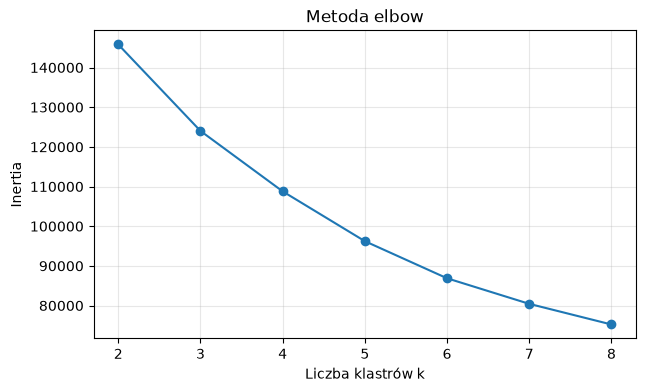

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(results_k["k"], results_k["inertia"], marker="o")
plt.xlabel("Liczba klastrów k")
plt.ylabel("Inertia")
plt.title("Metoda elbow")
plt.grid(alpha=0.3)
plt.show()


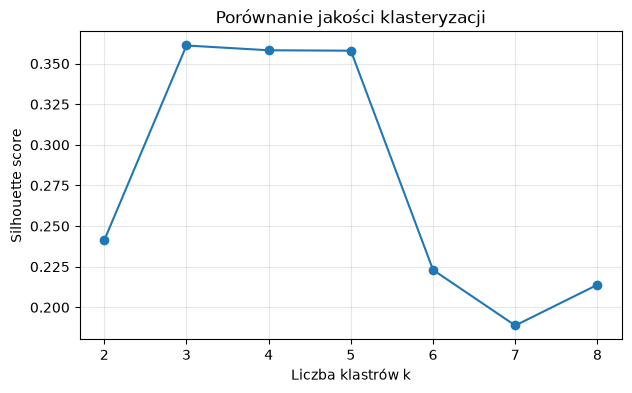

In [24]:
plt.figure(figsize=(7, 4))
plt.plot(results_k["k"], results_k["silhouette"], marker="o")
plt.xlabel("Liczba klastrów k")
plt.ylabel("Silhouette score")
plt.title("Porównanie jakości klasteryzacji")
plt.grid(alpha=0.3)
plt.show()


### Wybierz `k`



In [25]:
# Wartość początkowa z przykładu. Po obejrzeniu wykresów elbow i silhouette
# sprawdź, czy k=4 jest uzasadnione dla danych Łęcznej.
# Wybrana liczba klastrów
k_final = 4

kmeans = KMeans(
    n_clusters=k_final,
    n_init=20,
    random_state=42
)

# K-means wykonujemy tylko dla PS posiadających komplet cech
labels_final = kmeans.fit_predict(X_scaled)

# Najpierw tworzymy pustą kolumnę dla wszystkich PS
df["cluster"] = pd.NA

# Etykiety przypisujemy tylko tym PS,
# które rzeczywiście uczestniczyły w K-means
df.loc[mask_kmeans, "cluster"] = labels_final

# Typ Int64 pozwala przechowywać liczby całkowite oraz brak <NA>
df["cluster"] = df["cluster"].astype("Int64")

print("Liczebność klastrów:")
print(df["cluster"].value_counts(dropna=False).sort_index())

Liczebność klastrów:
cluster
0    43110
1    10241
2      480
3     8395
Name: count, dtype: Int64


C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\817607552.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["cluster"] = pd.NA


## Charakterystyka klastrów

Po tej analizie można nadać klastrom opisowe nazwy, np. „regularne osiadanie” czy „zmienne tempo”, jeśli dane rzeczywiście to pokazują.


In [26]:
print("Liczebność klastrów:")
print(df["cluster"].value_counts().sort_index())

cluster_summary = (
    df.groupby("cluster")[model_features + ["rmse_ts", "anomaly_score"]]
      .median()
      .round(3)
)

cluster_summary


Liczebność klastrów:
cluster
0    43110
1    10241
2      480
3     8395
Name: count, dtype: Int64


,mean_velocity,acceleration,trend_change,rmse_ts,anomaly_score
cluster,,,,,
0,-0.5,-0.02,-0.016,1.2,0.357
1,-0.4,0.58,3.228,2.0,0.434
2,-8.7,0.03,1.230,2.3,0.623
3,-0.4,-0.65,-3.670,2.1,0.453


## PCA — wizualizacja klastrów w dwóch wymiarach

PCA służy tylko do pokazania wielowymiarowych danych na płaszczyźnie. Kompresuje informację zawartą w wielu cechach do dwóch nowych wymiarów, dzięki czemu możemy zwizualizować wielowymiarowe dane na płaszczyźnie.



C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\2966130753.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["PC1"] = np.nan
C:\Users\Patrick_Ingibitor\AppData\Local\Temp\ipykernel_20936\2966130753.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["PC2"] = np.nan


Wyjaśniona wariancja PC1 + PC2: 82.3 %


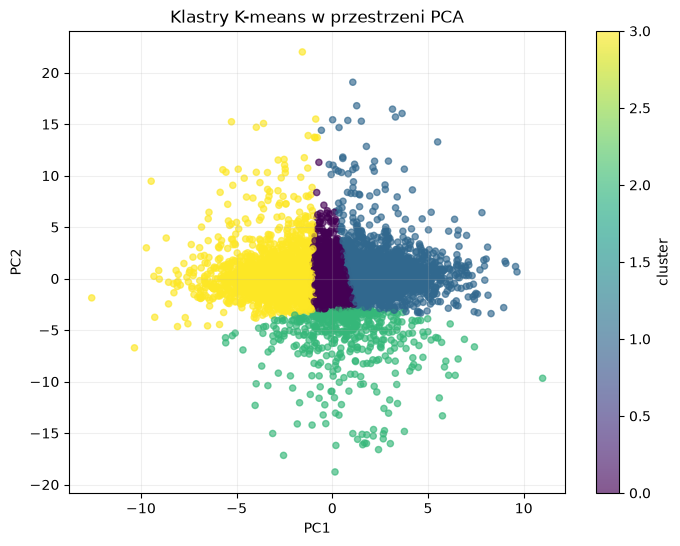

In [27]:
# PCA wykonujemy na tych samych PS,
# które zostały wykorzystane w K-means

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Tworzymy puste kolumny dla wszystkich PS
df["PC1"] = np.nan
df["PC2"] = np.nan

# Wyniki PCA przypisujemy tylko punktom,
# które uczestniczyły w K-means
df.loc[mask_kmeans, "PC1"] = X_pca[:, 0]
df.loc[mask_kmeans, "PC2"] = X_pca[:, 1]

print(
    "Wyjaśniona wariancja PC1 + PC2:",
    round(
        pca.explained_variance_ratio_.sum() * 100,
        1
    ),
    "%"
)

# Do wykresu bierzemy tylko PS posiadające wynik PCA i klaster
df_pca = df.loc[mask_kmeans].copy()

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df_pca["PC1"],
    df_pca["PC2"],
    c=df_pca["cluster"].astype(int),
    alpha=0.65,
    s=20
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Klastry K-means w przestrzeni PCA")

plt.colorbar(
    scatter,
    label="cluster"
)

plt.grid(alpha=0.2)
plt.show()

## Przykładowe szeregi z każdego klastra



KLASTER 0


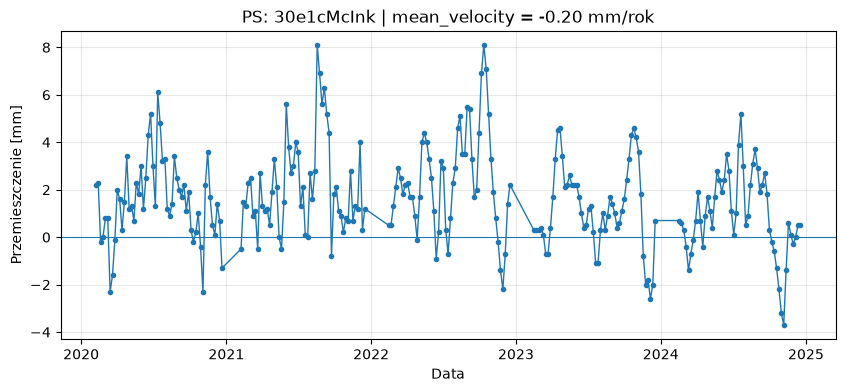

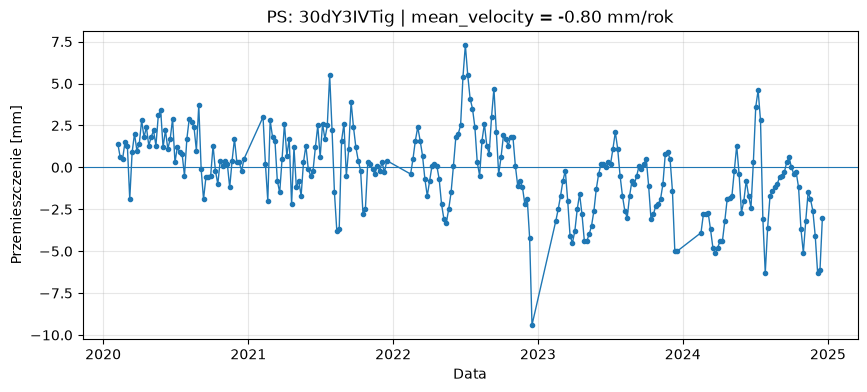

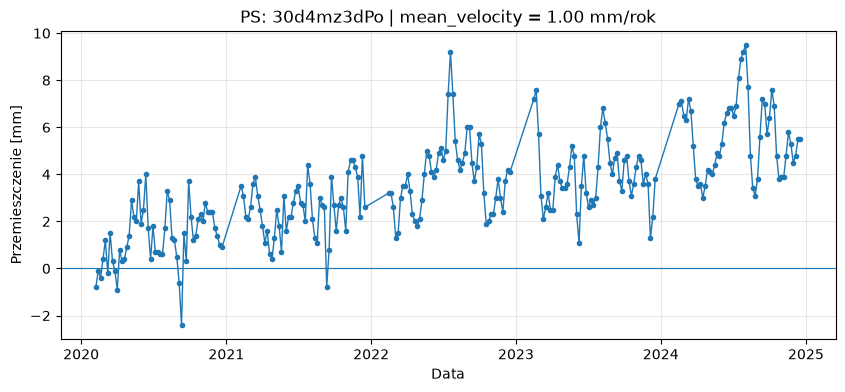


KLASTER 1


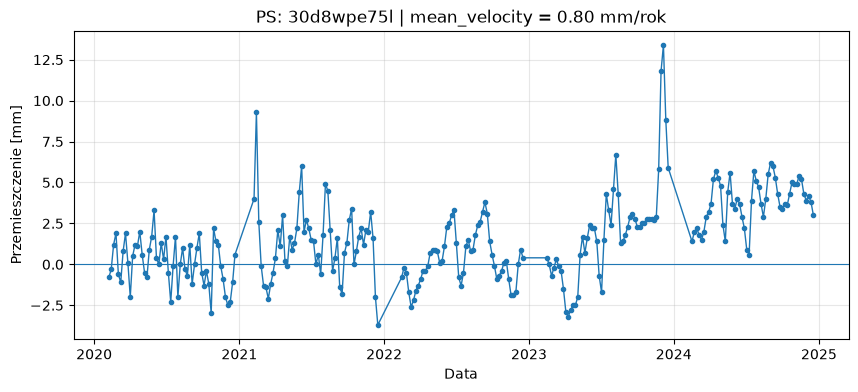

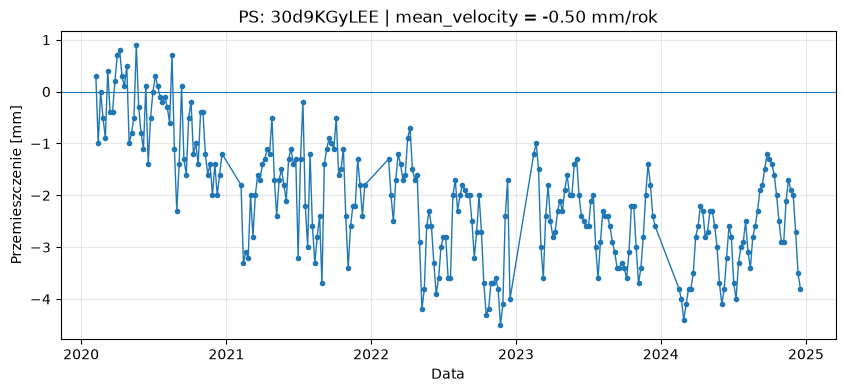

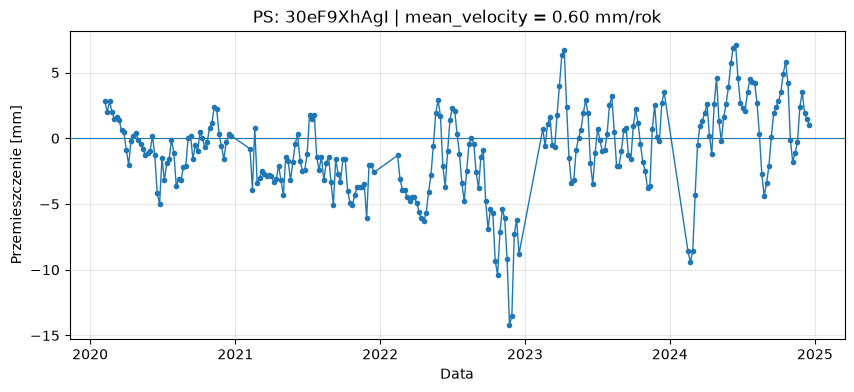


KLASTER 2


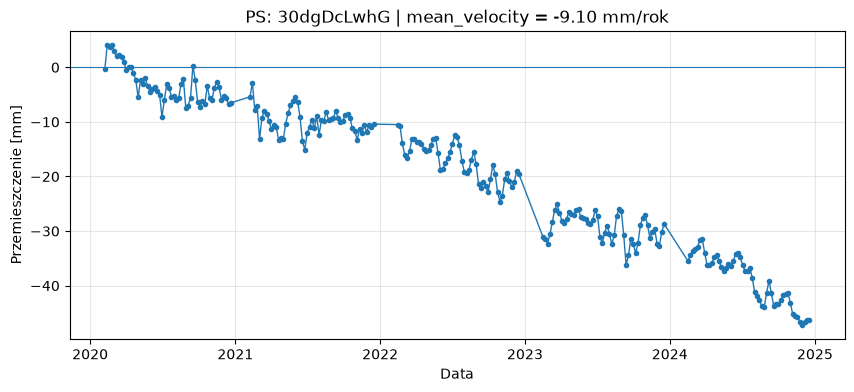

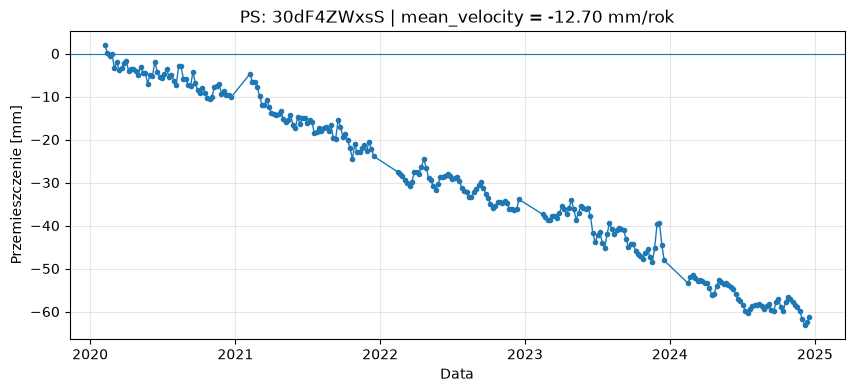

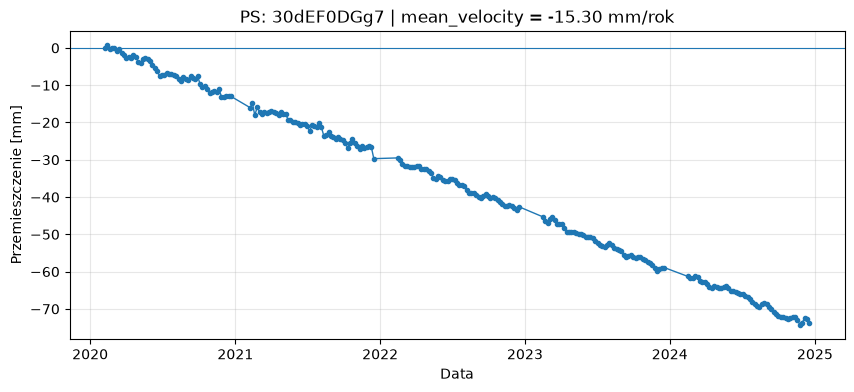


KLASTER 3


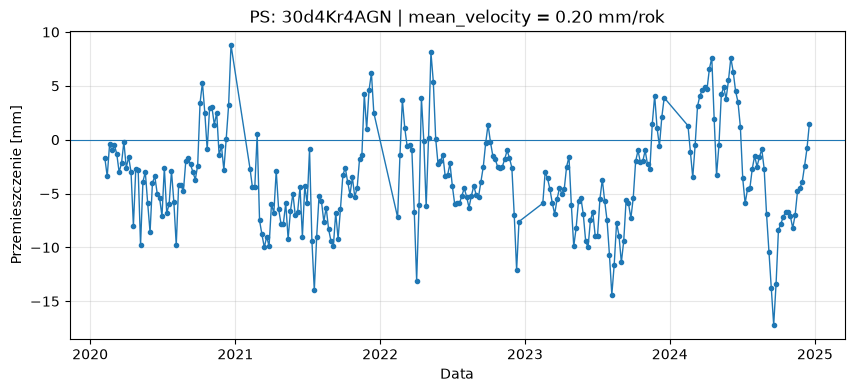

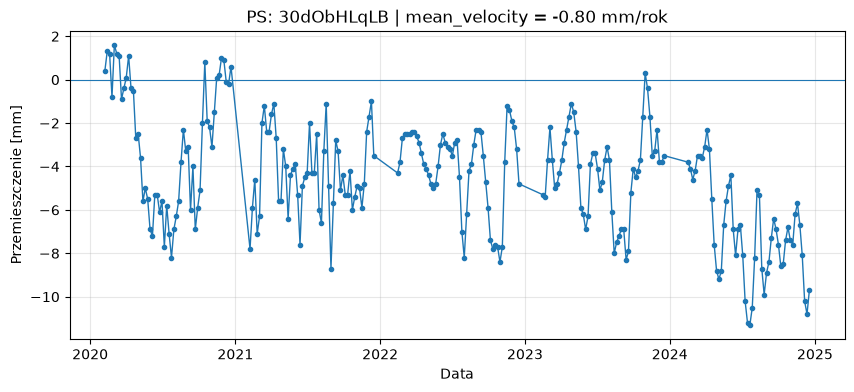

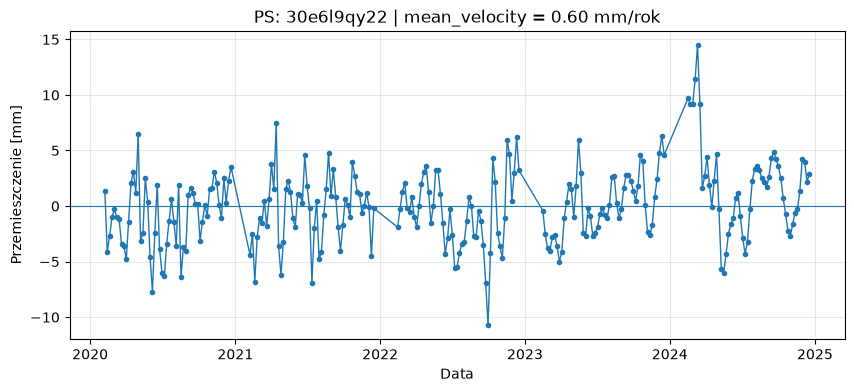

In [28]:
# Analizujemy tylko PS, które mają przypisany klaster
df_clustered = df.dropna(subset=["cluster"]).copy()

for cluster_id in sorted(df_clustered["cluster"].unique()):

    print("\nKLASTER", cluster_id)

    cluster_points = df_clustered[
        df_clustered["cluster"] == cluster_id
    ]

    sample = cluster_points.sample(
        n=min(3, len(cluster_points)),
        random_state=42
    )

    for pid in sample["pid"]:
        plot_ps(pid)

# ETAP 6 — Zestawienie wyników Isolation Forest i K-means

Obie metody opisują inne aspekty danych:

- `anomaly_score` — **jak nietypowy** jest PS,
- `cluster` — **do jakiego typu zachowania** jest najbardziej podobny.

Sprawdzamy więc, czy nietypowe PS koncentrują się w określonych klastrach.


In [29]:
cluster_model_summary = (
    df.groupby("cluster")
    .agg(
        n_PS=("pid", "count"),
        median_velocity=("mean_velocity", "median"),
        median_acceleration=("acceleration", "median"),
        median_trend_change=("trend_change", "median"),
        median_anomaly_score=("anomaly_score", "median"),
        max_anomaly_score=("anomaly_score", "max"),
        median_rmse=("rmse_ts", "median")
    )
    .round(3)
)

cluster_model_summary

,n_PS,median_velocity,median_acceleration,median_trend_change,median_anomaly_score,max_anomaly_score,median_rmse
cluster,,,,,,,
0,43110,-0.5,-0.02,-0.016,0.357,0.730,1.2
1,10241,-0.4,0.58,3.228,0.434,0.765,2.0
2,480,-8.7,0.03,1.230,0.623,0.788,2.3
3,8395,-0.4,-0.65,-3.670,0.453,0.798,2.1


In [30]:
cluster_anomalies = df.groupby("cluster").agg(
    n_PS=("pid", "count"),
    n_anomalies=("anomaly", "sum"),
    median_anomaly_score=("anomaly_score", "median")
)

cluster_anomalies["percent_anomalies"] = (
    cluster_anomalies["n_anomalies"]
    / cluster_anomalies["n_PS"]
    * 100
).round(1)

cluster_anomalies

,n_PS,n_anomalies,median_anomaly_score,percent_anomalies
cluster,,,,
0,43110,193,0.357065,0.4
1,10241,1180,0.434449,11.5
2,480,407,0.623244,84.8
3,8395,1332,0.453443,15.9


# ETAP 7 — Eksport do QGIS

Eksportujemy danych do QGIS.

In [31]:
export_cols = [
    "pid",
    "easting",
    "northing",
    "mean_velocity",
    "acceleration",
    "seasonality",
    "rmse_ts",
    "trend",
    "trend_R2",
    "baseline_velocity",
    "recent_velocity",
    "trend_change",
    "anomaly_score",
    "anomaly",
    "cluster"
]

# Kontrola obecności wymaganych kolumn
missing_cols = [
    col for col in export_cols
    if col not in df.columns
]

if missing_cols:
    raise ValueError(
        f"Brakujące kolumny: {missing_cols}"
    )

df[export_cols].to_csv(
    OUTPUT_CSV,
    index=False
)

print(f"Zapisano wyniki PS: {OUTPUT_CSV}")

Zapisano wyniki PS: EGMS_Leczna_results.csv
